# Predicting the three current RAPID responses

**Standalone variables and compact selection** now precede the existing grouped benchmark and removal diagnostics. We seek a small useful set, rather than interpreting small individual removal losses as evidence that every variable is unimportant.

The three responses remain **lag, 1% plateau event duration and peak excess**. All predictors use geometry or the permitted reference slope. No response, routing time, numerical flag or forcing duration is used as an input.

Read in order:

1. Equations and domain scope.
2. Each variable alone, alongside within-treatment correlations.
3. Small combinations and their accuracy–complexity tradeoff.
4. Parent-to-child changes and surrounding-network lengths as separate additions.
5. The existing grouped benchmark, removal losses, and model/treatment transfer checks.
6. Out-of-range evaluation on the width/length and fixed-unit embedding extension, without fitting to extension rows.

Selection uses **four geometry-group folds within development data**. Held-out results are calculated afterward. The holdout has been used in earlier exploratory studies, so it is not a new independent confirmation set. One shared model is fitted across treatments; treatment labels are not predictors. Summary R² averages the seven treatment-specific scores equally.

See [the equations](../GEOMETRIC_PREDICTORS.md), [the sensitivity synthesis](synthetic_results_synthesis.ipynb), and [current response definitions](../../RAPID/CURRENT_RESPONSE_METRICS.md).

**Checkpoint · 29 September 2026:** [SYN-2026-09-29](../notes/2026-09-29_synthetic_checkpoint.md) records the findings, the pause pending real-case comparison, and the restart of hydraulic applicability.

**Current synthetic version · 30 September 2026:** BASED reference depth, local width–depth exponent **α=0.65**, Manning n=0.035, X=0.1 and 200m segmentation/floor. Responses and local-kb resistance are recomputed from the versioned routing run. Geometry and validation partitions are unchanged. **Real-case comparison is deferred until the updated-slope runs.** Earlier outputs are preserved separately; the old-versus-new comparison changes the complete hydraulic setup, not alpha alone.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm,TwoSlopeNorm,Normalize
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'synthetic_experiments').exists())
import sys
sys.path.insert(0,str(ROOT/'synthetic_experiments/investigations'))
from analysis_paths import results_root
ACTIVE_RUN=results_root()/'full_grid_island'
ACTIVE_EXTENSION=results_root()/'embedded_width_length_extension'
assert json.loads((ACTIVE_RUN/'manifest.json').read_text())['config']['selected_hydraulic_reference']['depth_alpha']==.65
OUT=ACTIVE_RUN/'current_analysis'
d=pd.read_parquet(OUT/'current_comparisons.parquet')
Y=['lag_shift_pct','event_duration_change_pct','peak_excess_change_pct']
YL=['Peak-lag change','Event-duration change','Peak-excess change']
FACTORS=['total_width_m','reference_slope','outer_a_fraction','inner_fraction','length_multiplier','total_length_m','internal_location']
FL=['Total width','Reference slope','Outer A fraction','Inner / crossover fraction','Branch length multiplier','Network extent','Internal location']
F=dict(zip(FACTORS,FL))
STATES=['simple/full','nested/inner_only','nested/main_island_only','nested/full','crossover/upstream_only','crossover/downstream_only','crossover/full']
SL=['Simple: full','Nested: inner','Nested: main island','Nested: full','Cross: upstream','Cross: downstream','Cross: full']
SN=dict(zip(STATES,SL))
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
def heat(ax,a,rows,cols,title,vmin,vmax,cmap='YlOrRd',fmt='.1f'):
    a=np.asarray(a,float);norm=TwoSlopeNorm(vmin=vmin,vcenter=0,vmax=vmax) if vmin<0<vmax else Normalize(vmin,vmax)
    im=ax.imshow(a,aspect='auto',norm=norm,cmap=cmap)
    ax.set_xticks(range(len(cols)),cols,rotation=40,ha='right',fontsize=8)
    ax.set_yticks(range(len(rows)),rows,fontsize=9);ax.set_title(title,loc='left',fontsize=11)
    for i,j in np.ndindex(a.shape):
        if np.isfinite(a[i,j]):
            color='white' if np.dot(im.cmap(im.norm(a[i,j]))[:3],[.2126,.7152,.0722])<.48 else '#222'
            ax.text(j,i,format(a[i,j],fmt),ha='center',va='center',fontsize=7,color=color)
    return im
def savefig(fig,name):
    fig.savefig(OUT/name,dpi=170,bbox_inches='tight');display(fig);plt.close(fig)

scores=pd.read_csv(OUT/'predictor_scores.csv')
features=json.loads((OUT/'predictor_features.json').read_text())
GROUPS=['omega','components','compact','omega_plus_all','components_plus_all']
GL=['Omega','R, length fraction, exposure','Omega + size/proportions + dominance','Omega + geometry + slope','Separate R/Lf/E + geometry + slope']
metric_names={'resistance_log':'Resistance R','length_fraction':'Length fraction','width_fraction':'Exposure','parent_equivalent_length':'Equivalent length','parent_elongation':'Elongation','parent_dominant_width_fraction':'Width dominance','parent_path_length_cv':'Path-length CV','signed_length_width_association':'Length–width association','domain_reference_slope':'Reference slope'}
display(pd.DataFrame({'Feature group':GL,'Inputs':[', '.join(metric_names.get(x,x) for x in features[k]) for k in GROUPS]}))


,Feature group,Inputs
0,Omega,omega
1,"R, length fraction, exposure","Resistance R, Length fraction, Exposure"
2,Omega + size/proportions + dominance,"omega, Equivalent length, Elongation, Width do..."
3,Omega + geometry + slope,"omega, Equivalent length, Elongation, Width do..."
4,Separate R/Lf/E + geometry + slope,"Resistance R, Length fraction, Exposure, Equiv..."


## 1. What the variables describe

For each directed path $p$ through the matched **parent domain**, let

$$L_p=\sum_{e\in p}\ell_e,\qquad W_p=\frac{\sum_{e\in p}\ell_e}{\sum_{e\in p}\ell_e/w_e},\qquad a_p=\frac{W_p}{\sum_jW_j}.$$

Then:

| Variable | Equation | Information |
|---|---|---|
| Equivalent length | $L_{eq}=\sum_pa_pL_p$ | Width-weighted length scale |
| Elongation | $L_{eq}/\sum_pW_p=\sum_pW_pL_p/(\sum_pW_p)^2$ | Length relative to equivalent width |
| Width dominance | $D_w=\max_p a_p$ | Unevenness of path widths |
| Path-length CV | $CV_L=\sqrt{\frac1n\sum_p(L_p-\bar L)^2}/\bar L$ | Relative length differences |
| Length–width association | $A_{LW}=L_{eq}/\bar L-1$ | Whether longer paths tend to be wider or narrower |
| Reference slope | $(H_{up}-H_{down})/(x_{down}-x_{up})$ | Synthetic boundary head gradient |

Here $\bar L$ is the unweighted mean path length. $A_{LW}=0$ when lengths are equal **or** widths are equal. For exactly two paths, $|A_{LW}|=(2D_w-1)CV_L$: these descriptors are complementary but algebraically related. This identity is verified on all 4,374 two-path comparisons in the dataset.

Length fraction uses domain channel length / whole-network channel length, counting each link once. Exposure is propagated from upstream using width allocation. These two already contain network context. Other descriptors refer to the matched domain: the inner unit for nested/inner-only, but the enclosing outer domain for main-island collapse and partial crossover comparisons. Shared links can occur in several enumerated paths; summed path width is not necessarily an actual cross-sectional width.

The tested change group contains $\log(L_{eq,c}/L_{eq,p})$, $\log(\mathcal E_c/\mathcal E_p)$, $CV_{L,c}-CV_{L,p}$ and $D_{w,c}-D_{w,p}$. The context group contains shortest directed physical lengths from inlet to domain entrance and from domain exit to outlet. These lengths do not describe every outside or bypass branch.

In [2]:
COMPACT=OUT/'compact_predictors'
selection=json.loads((COMPACT/'selection.json').read_text())
cv=pd.read_csv(COMPACT/'development_scores.csv')
held=pd.read_csv(COMPACT/'held_out_scores.csv')
correlations=pd.read_csv(COMPACT/'development_correlations.csv')
rank=pd.read_csv(COMPACT/'development_ranking.csv').set_index('feature_set')
named=selection['named_sets'];feature_sets=selection['features']
core=['omega','resistance_log','length_fraction','width_fraction','parent_equivalent_length','parent_elongation','parent_dominant_width_fraction','parent_path_length_cv','signed_length_width_association','domain_reference_slope']
names={'omega':'Omega','resistance_log':'Resistance R','length_fraction':'Length fraction','width_fraction':'Exposure','parent_equivalent_length':'Equivalent length','parent_elongation':'Elongation','parent_dominant_width_fraction':'Width dominance Dw','parent_path_length_cv':'Path-length CV','signed_length_width_association':'Length–width association A','domain_reference_slope':'Reference slope','log_equivalent_length_ratio':'Change: log length ratio','log_elongation_ratio':'Change: log elongation ratio','change_path_length_cv':'Change: path-length CV','change_width_dominance':'Change: width dominance','upstream_shortest_length_m':'Upstream shortest length','downstream_shortest_length_m':'Downstream shortest length'}
def short_set(key):return ' + '.join(names[c] for c in feature_sets[key])
def mean_score(frame,key):return frame[frame.feature_set==key].groupby('response').r2.mean().reindex(Y)


## 2. Each variable alone: prediction and association

The first figure is **held-out predictive strength using one input at a time**, under the same fixed boosted model used in the current benchmark. It is not the loss after removal from a full model. Because the model is shared across treatments, negative R² can occur even where a variable has a useful within-treatment relationship. It is not a separately optimized model for each treatment.

The second figure shows **Spearman correlation within each treatment on development data**. Pearson correlations are also saved. Correlation describes direction and monotonic association; it neither adds to model R² nor captures arbitrary interactions. Blank cells indicate a constant or numerically constant input. The two figures answer different questions.

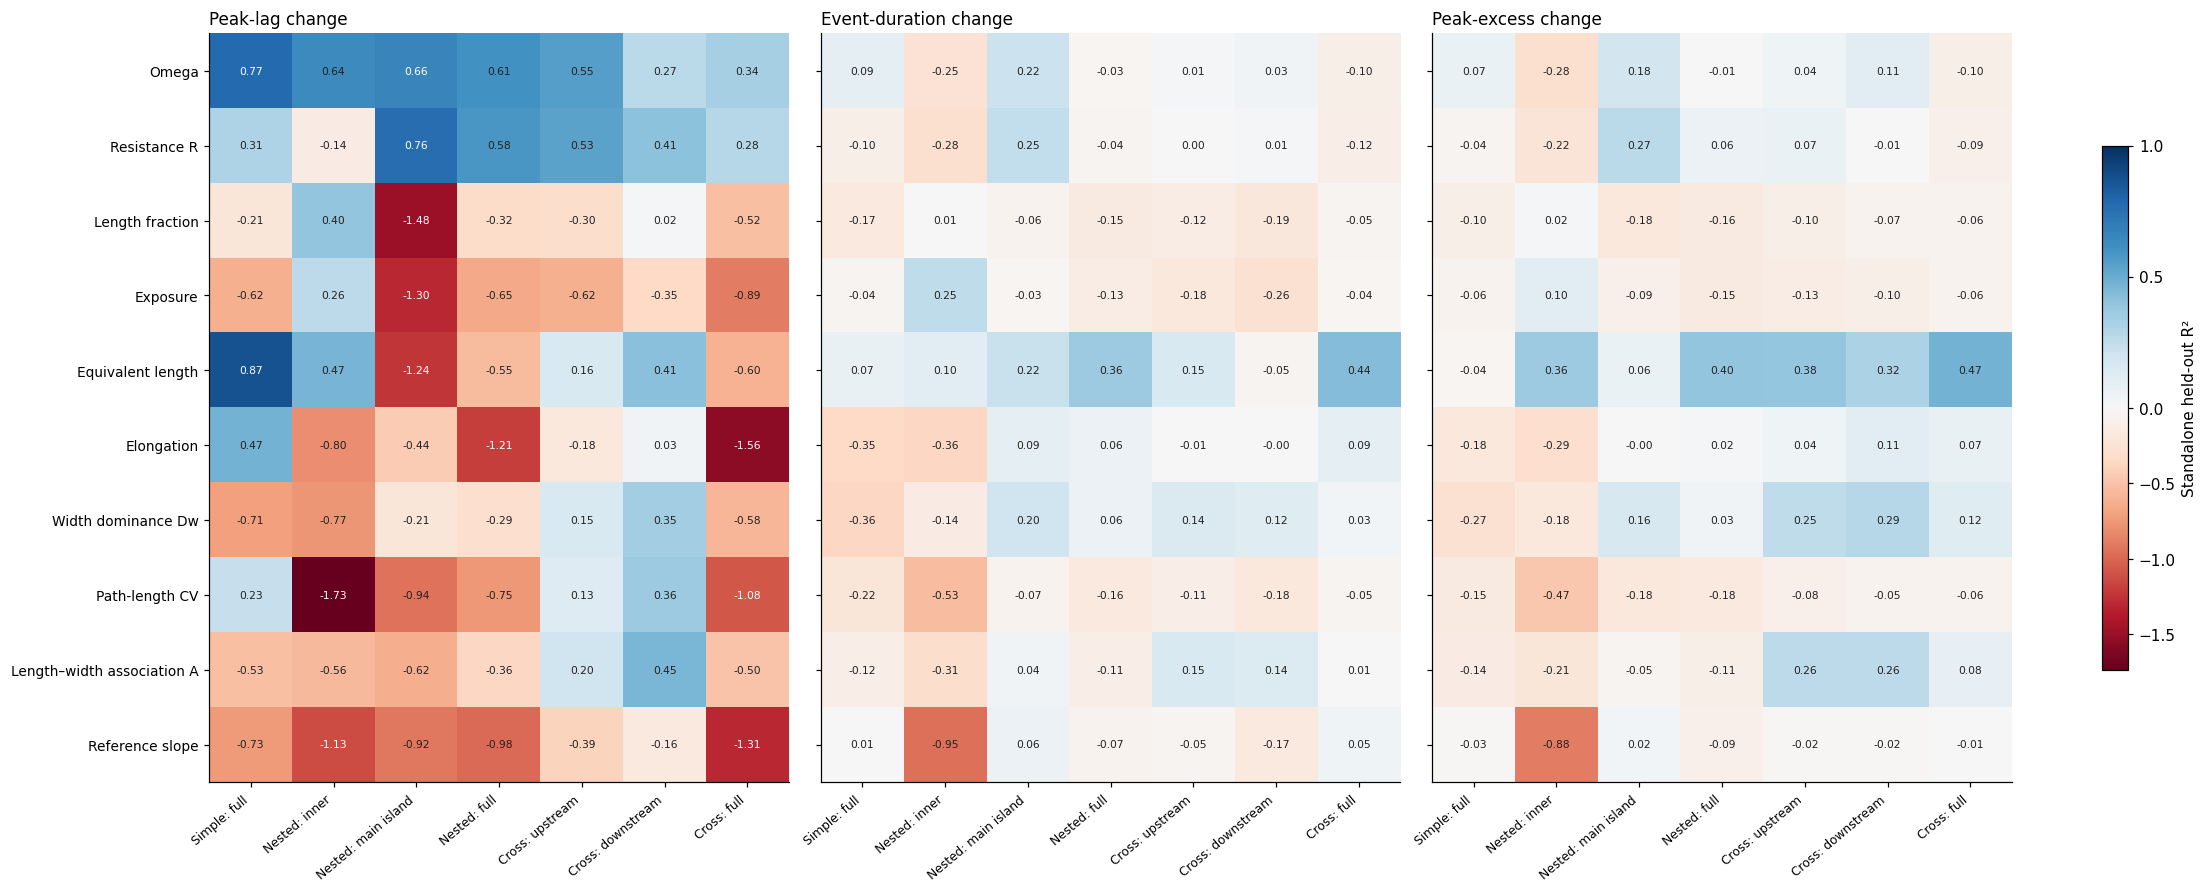

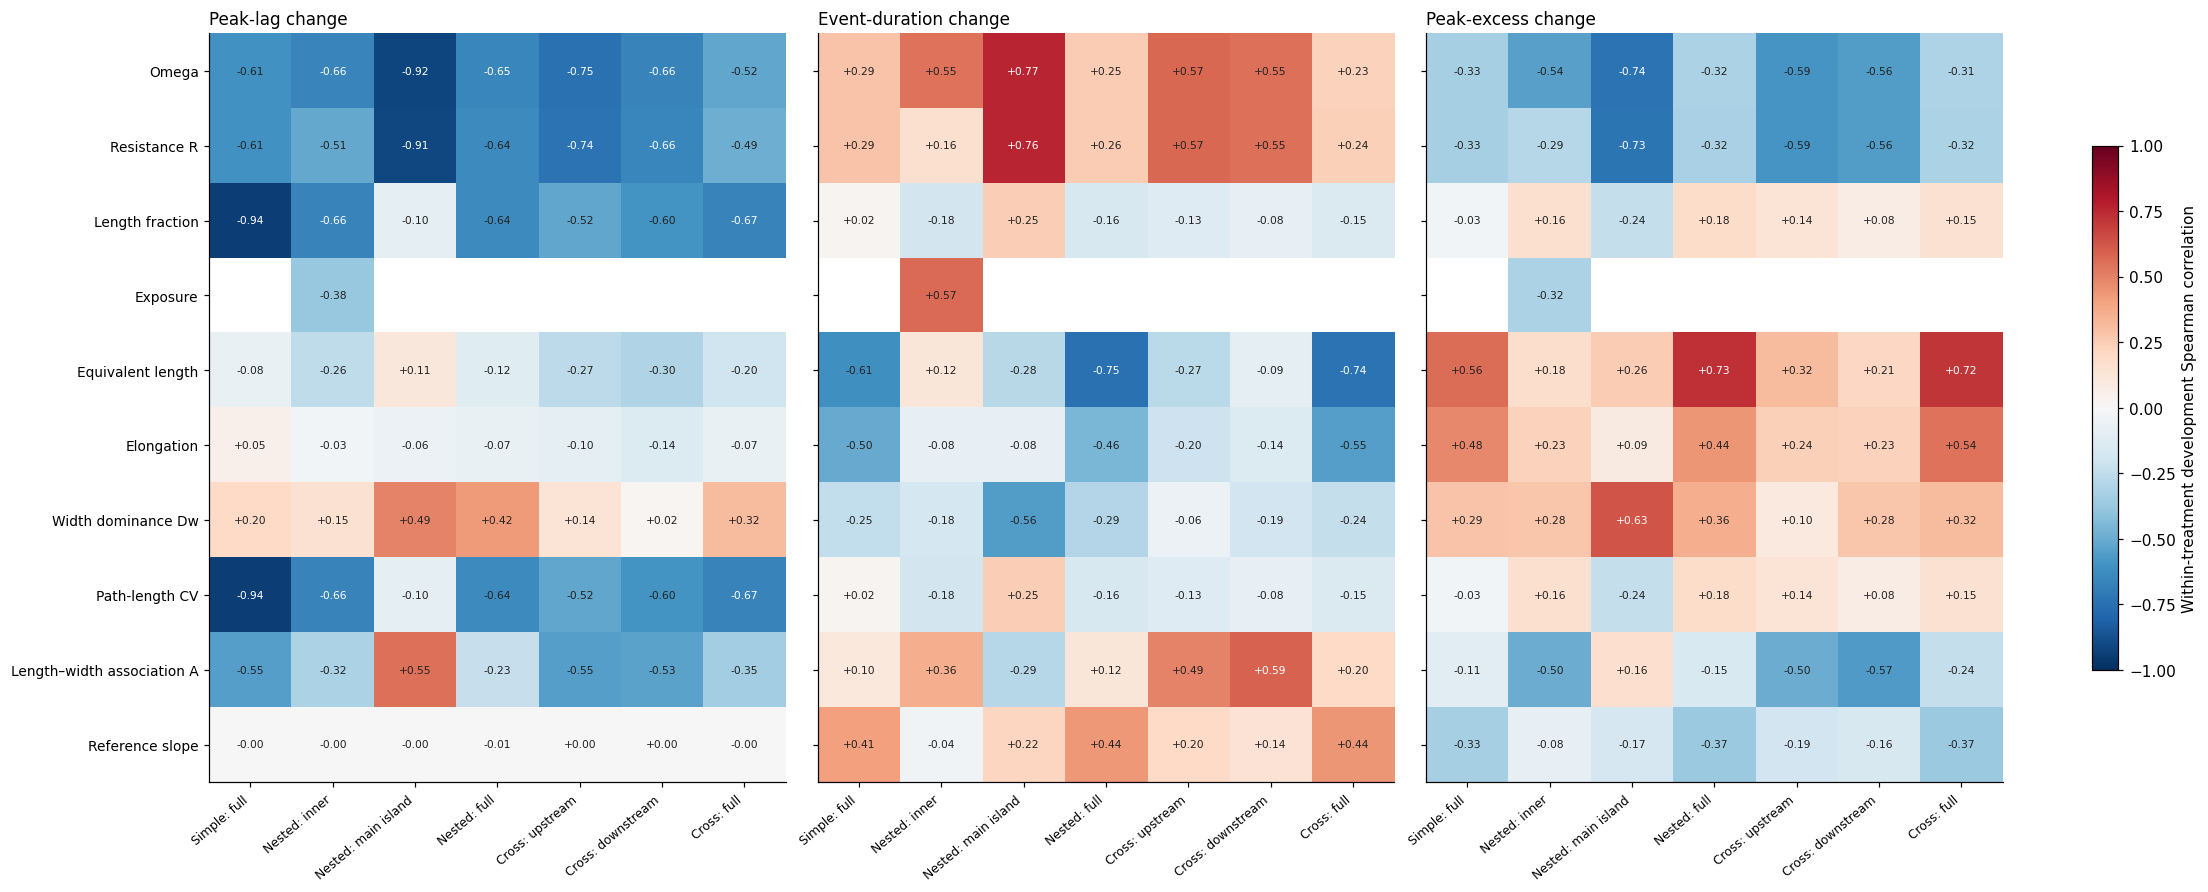

,Simple/full lag R² or R² loss
Omega alone,0.774
Resistance alone,0.312
Full model,0.985
Full model without resistance,0.988
Removal loss,-0.003


In [3]:
solo=held[held.feature_set.isin(core)]
fig,axes=plt.subplots(1,3,figsize=(20,8),constrained_layout=True)
low=min(-.25,float(solo.r2.min()))
for j,(ax,y,label) in enumerate(zip(axes,Y,YL)):
    mat=solo[solo.response==y].pivot(index='feature_set',columns='child_state',values='r2').reindex(index=core,columns=STATES)
    im=heat(ax,mat,[names[c] for c in core] if j==0 else ['']*len(core),SL,label,low,1,'RdBu',fmt='.2f')
fig.colorbar(im,ax=axes,label='Standalone held-out R²',shrink=.7)
savefig(fig,'compact_standalone_strength.png')
fig,axes=plt.subplots(1,3,figsize=(20,8),constrained_layout=True)
for j,(ax,y,label) in enumerate(zip(axes,Y,YL)):
    mat=correlations[(correlations.response==y)&(correlations.child_state!='pooled')].pivot(index='feature',columns='child_state',values='spearman').reindex(index=core,columns=STATES)
    im=heat(ax,mat,[names[c] for c in core] if j==0 else ['']*len(core),SL,label,-1,1,'RdBu_r',fmt='+.2f')
fig.colorbar(im,ax=axes,label='Within-treatment development Spearman correlation',shrink=.7)
savefig(fig,'compact_standalone_correlations.png')
# Concrete example explaining the earlier confusion.
old_scores=scores[(scores.validation=='geometry_group_holdout')&(scores.model=='boosted')&(scores.child_state=='simple/full')&(scores.response=='lag_shift_pct')].set_index('feature_set').r2
example=pd.Series({'Omega alone':old_scores['omega'],'Resistance alone':old_scores['resistance_only'],'Full model':old_scores['components_plus_all'],'Full model without resistance':old_scores['drop_resistance_log'],'Removal loss':old_scores['components_plus_all']-old_scores['drop_resistance_log']})
display(example.rename('Simple/full lag R² or R² loss').round(3).to_frame())


## 3. Find a small useful combination

Search all **175 one-, two- and three-input combinations** from the ten existing candidate axes. Then use forward addition to six inputs and backward removal from the nine-input reference to three. These larger searches are greedy; they do not prove a globally minimal subset. Fixed compact and arrangement-only reference sets are also evaluated.

Each candidate is scored using four development folds, with identical parent–child geometry groups kept together. The shared objective averages R² equally across three responses and seven treatments. The selected shared set is the smallest evaluated set within **0.02 R² of the best-mean candidate for every response**. Response-specific selections use the same 0.02 tolerance for their own response.

Omega counts as one constructed input axis but uses three underlying components. Axis count is therefore not measurement cost. Combinations here are **separate model inputs**, not multiplied scalar products.

The plots show the best shared-mean set found at each size. Development and held-out scores are shown separately; held-out results do not choose the sets.

Selected shared set: Resistance R + Exposure + Equivalent length + Width dominance Dw + Length–width association A + Reference slope
Selection used development data only. Smallest among evaluated sets, not a global minimality proof.


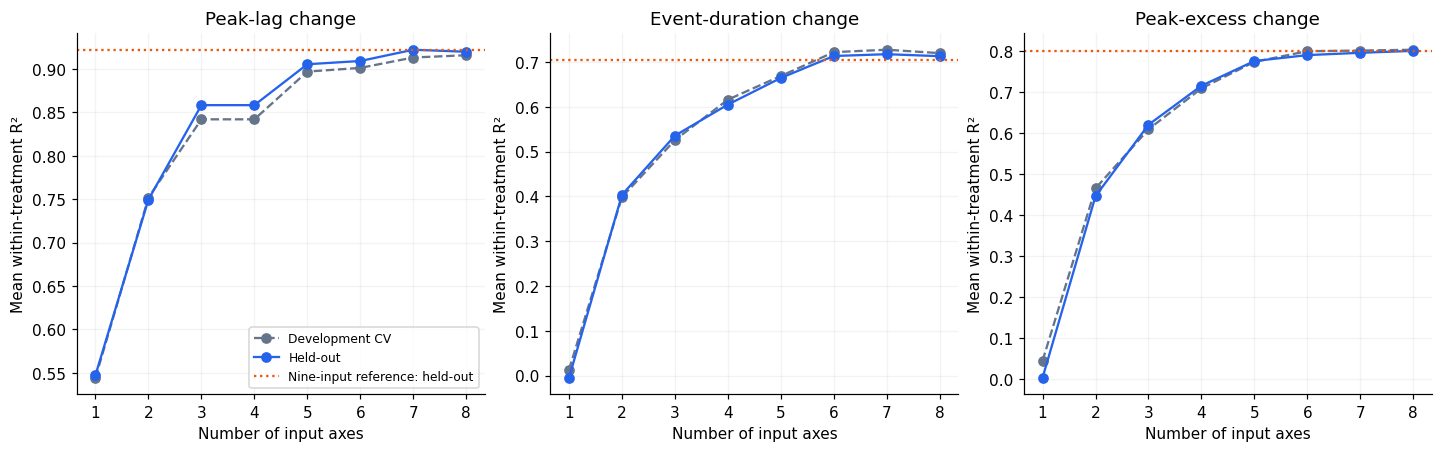

,n_axes,features,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct
1,1,Omega,0.547,-0.005,0.003
3,2,Omega + Equivalent length,0.749,0.404,0.446
5,3,Omega + Equivalent length + Width dominance Dw,0.858,0.536,0.620
7,4,Omega + Equivalent length + Width dominance Dw...,0.858,0.605,0.715
9,5,Omega + Equivalent length + Width dominance Dw...,0.905,0.664,0.776
11,6,Resistance R + Exposure + Equivalent length + ...,0.909,0.713,0.790
13,7,Resistance R + Exposure + Equivalent length + ...,0.922,0.717,0.796
15,8,Resistance R + Length fraction + Exposure + Eq...,0.920,0.713,0.801


,selection,n_axes,features,lag_shift_pct_CV,lag_shift_pct_held_out,event_duration_change_pct_CV,event_duration_change_pct_held_out,peak_excess_change_pct_CV,peak_excess_change_pct_held_out
0,selected_shared,6,Resistance R + Exposure + Equivalent length + ...,0.901,0.909,0.722,0.713,0.800,0.790
1,selected_lag_shift_pct,4,Omega + Width dominance Dw + Path-length CV + ...,0.911,0.918,0.209,0.217,0.278,0.284
2,selected_event_duration_change_pct,6,Resistance R + Exposure + Equivalent length + ...,0.901,0.909,0.722,0.713,0.800,0.790
3,selected_peak_excess_change_pct,6,Resistance R + Exposure + Equivalent length + ...,0.901,0.909,0.722,0.713,0.800,0.790


In [4]:
budget_labels=sorted([k for k in named if k.startswith('best_') and k.endswith('_axes')],key=lambda k:int(k.split('_')[1]))
rows=[]
for label in budget_labels:
    key=named[label]
    for split,frame in [('Development CV',cv),('Held-out',held)]:
        row=mean_score(frame,key).to_dict();row.update(n_axes=len(feature_sets[key]),split=split,features=short_set(key));rows.append(row)
curve=pd.DataFrame(rows)
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for ax,y,label in zip(axes,Y,YL):
    for split,color,style in [('Development CV','#64748b','--'),('Held-out','#2563eb','-')]:
        g=curve[curve.split==split].sort_values('n_axes');ax.plot(g.n_axes,g[y],'o',ls=style,color=color,label=split)
    reference=mean_score(held,named['full_reference'])[y]
    ax.axhline(reference,color='#ea580c',ls=':',label='Nine-input reference: held-out')
    ax.set(title=label,xlabel='Number of input axes',ylabel='Mean within-treatment R²');ax.grid(alpha=.15)
axes[0].legend(fontsize=8);savefig(fig,'compact_accuracy_complexity.png')
display(curve[curve.split=='Held-out'][['n_axes','features',*Y]].round(3))
selected_rows=[]
for label in ['selected_shared',*[f'selected_{y}' for y in Y]]:
    key=named[label];row=dict(selection=label,n_axes=len(feature_sets[key]),features=short_set(key))
    for y in Y:
        row[y+'_CV']=rank.loc[key,y];row[y+'_held_out']=mean_score(held,key)[y]
    selected_rows.append(row)
display(pd.DataFrame(selected_rows).round(3))
print('Selected shared set:',short_set(named['selected_shared']))
print('Selection used development data only. Smallest among evaluated sets, not a global minimality proof.')


## 4. Test geometric change and surrounding-network information separately

Add the four parent-to-child descriptors or the two surrounding lengths to (a) the existing compact reference and (b) the development-selected shared set. These blocks are assessed separately after the original subset search and are not retroactively used to select its winner.

This asks whether describing **what is retained or removed** is more informative than describing the parent alone, and whether additional upstream/downstream geometry helps. The new context lengths overlap existing scale information in this constrained grid; weak improvement would not establish irrelevance in real rivers.

Scores below are held out by geometry group. They remain exploratory because this holdout has been inspected in earlier studies.

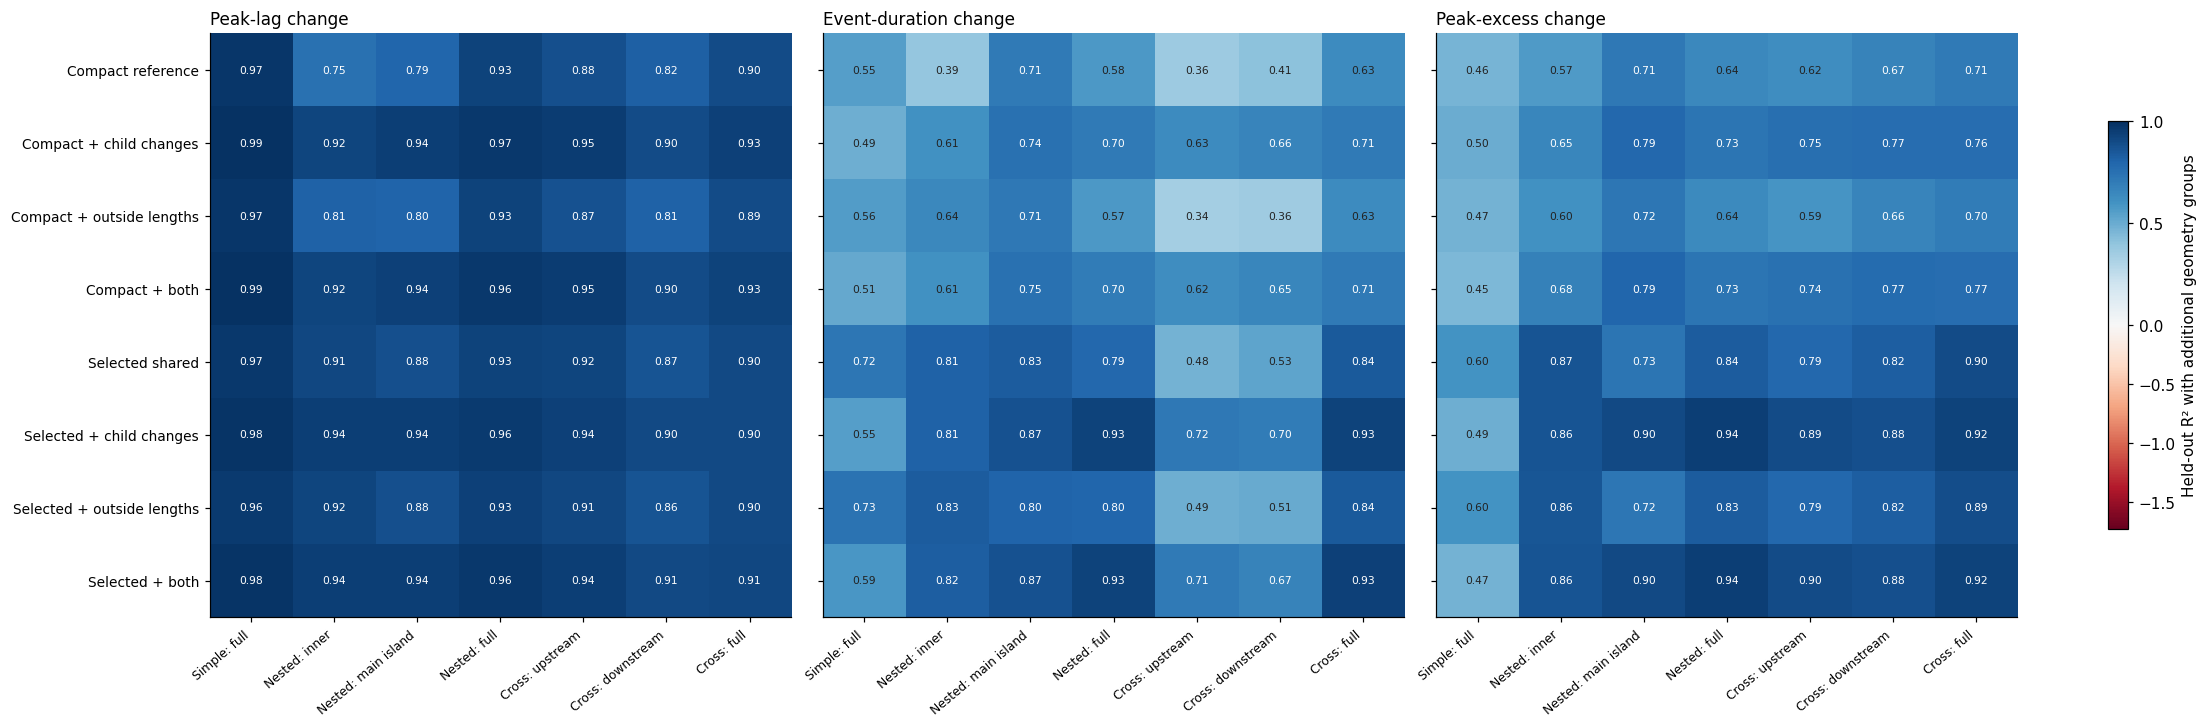

response,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct
group,,,
Compact reference,0.861,0.519,0.626
Compact + child changes,0.941,0.649,0.707
Compact + outside lengths,0.868,0.544,0.626
Compact + both,0.940,0.649,0.705
Selected shared,0.909,0.713,0.790
Selected + child changes,0.937,0.786,0.841
Selected + outside lengths,0.909,0.715,0.787
Selected + both,0.941,0.789,0.839


In [5]:
labels=['compact_reference','compact_plus_change','compact_plus_context','compact_plus_change_context','selected_shared','selected_plus_change','selected_plus_context','selected_plus_change_context']
readable=['Compact reference','Compact + child changes','Compact + outside lengths','Compact + both','Selected shared','Selected + child changes','Selected + outside lengths','Selected + both']
fig,axes=plt.subplots(1,3,figsize=(20,6.5),constrained_layout=True)
block_rows=[]
for tag,name in zip(labels,readable):
    key=named[tag]
    for response,value in mean_score(held,key).items():block_rows.append(dict(group=name,response=response,r2=value,n_axes=len(feature_sets[key])))
for j,(ax,y,label) in enumerate(zip(axes,Y,YL)):
    keys=[named[tag] for tag in labels]
    rows=[held[(held.feature_set==key)&(held.response==y)].set_index('child_state').r2.reindex(STATES).to_numpy() for key in keys]
    mat=np.array(rows);im=heat(ax,mat,readable if j==0 else ['']*len(labels),SL,label,min(-.25,float(held.r2.min())),1,'RdBu',fmt='.2f')
fig.colorbar(im,ax=axes,label='Held-out R² with additional geometry groups',shrink=.7)
savefig(fig,'compact_change_context.png')
display(pd.DataFrame(block_rows).pivot(index='group',columns='response',values='r2').reindex(readable)[Y].round(3))


### Transfer check for the new groups

Withhold an entire collapse treatment and train on the other six. The recalculated table distinguishes within-grid interpolation from treatment transfer. These transfer scores are exploratory diagnostics, not an independent river validation, and do not choose subsets.

In [6]:
transfer=pd.read_csv(COMPACT/'omitted_treatment_scores.csv')
display(transfer.groupby(['label','response']).r2.mean().unstack()[Y].round(3))
display(transfer[transfer.label=='selected_plus_change'].pivot(index='child_state',columns='response',values='r2').reindex(STATES)[Y].round(3))


response,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct
label,,,
compact_plus_change,0.390,0.145,0.369
compact_reference,0.299,-0.044,0.206
selected_plus_change,-0.245,0.245,0.502
selected_plus_change_context,-0.242,0.260,0.509
selected_shared,-0.356,0.184,0.441


response,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct
child_state,,,
simple/full,0.406,-0.205,0.138
nested/inner_only,-6.137,-0.131,0.205
nested/main_island_only,0.627,0.433,0.429
nested/full,0.887,0.622,0.791
crossover/upstream_only,0.860,0.300,0.596
crossover/downstream_only,0.796,0.096,0.629
crossover/full,0.844,0.601,0.726


## Current compact-selection result

The preceding tables report the newly selected variables and held-out scores. The same candidate list, estimator and four development folds are reused; no extension observations enter selection. The chosen number of inputs may differ from the earlier hydraulic setup.

## 5. Overall predictive strength by collapse treatment

Compare the same model and geometry-group split across feature groups. Separate resistance, length fraction and exposure are compared with their omega product. The figures show predictive information, not independently causal contributions.

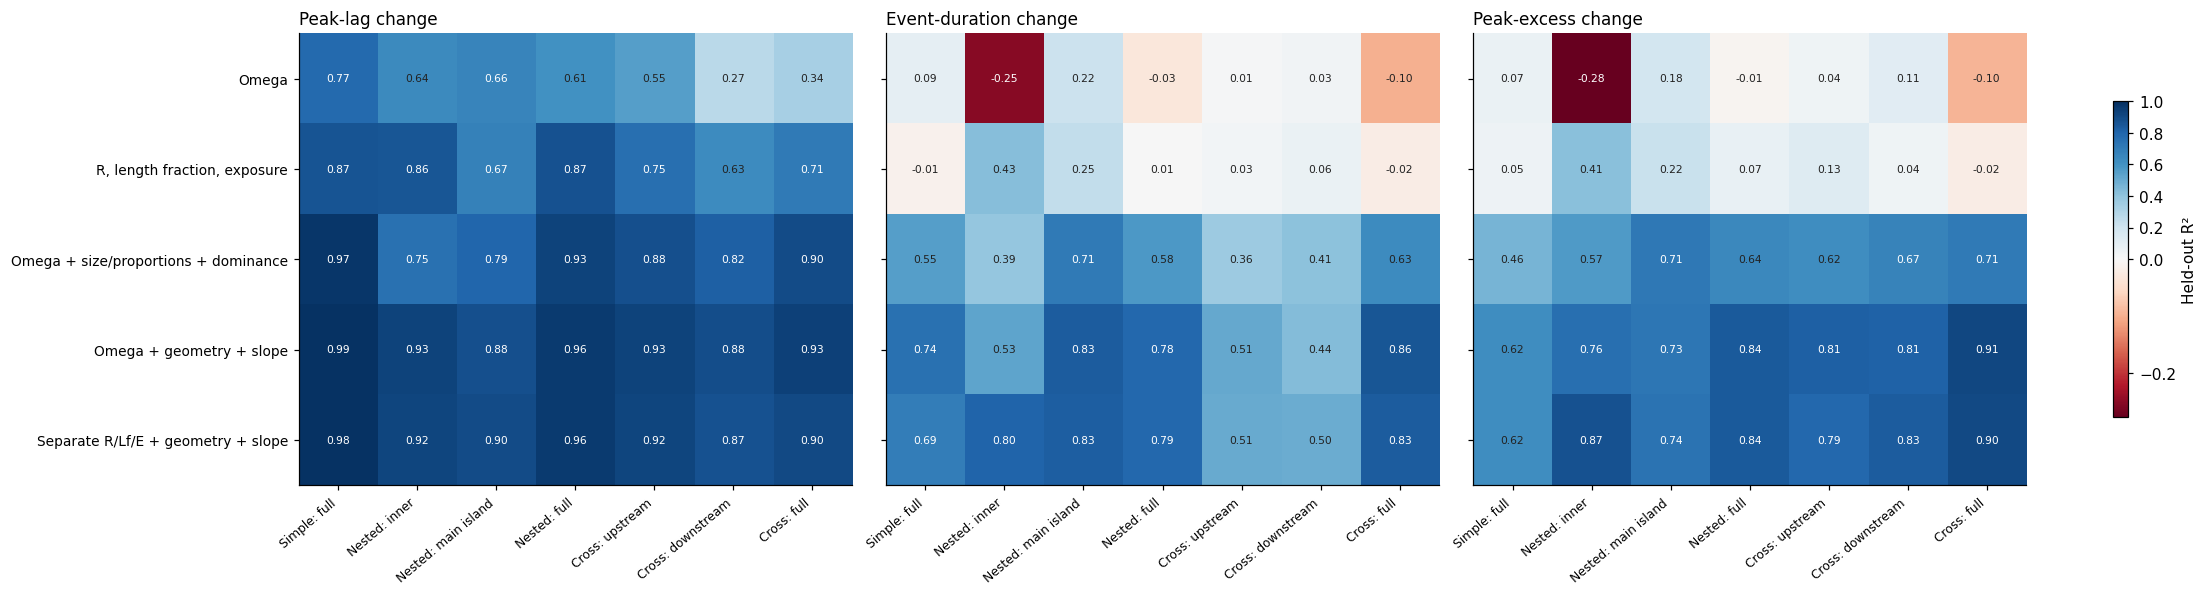

response,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct
feature_set,,,
omega,0.547,-0.005,0.003
components,0.765,0.106,0.130
compact,0.861,0.519,0.626
omega_plus_all,0.929,0.670,0.782
components_plus_all,0.921,0.705,0.799


In [7]:
s=scores[(scores.validation=='geometry_group_holdout')&(scores.model=='boosted')&scores.feature_set.isin(GROUPS)&(scores.child_state!='pooled')]
fig,axes=plt.subplots(1,3,figsize=(20,5.3),constrained_layout=True)
low=min(-.25,float(s.r2.min()))
for j,(ax,y,label) in enumerate(zip(axes,Y,YL)):
    mat=s[s.response==y].pivot(index='feature_set',columns='child_state',values='r2').reindex(index=GROUPS,columns=STATES)
    im=heat(ax,mat,GL if j==0 else ['']*len(GL),SL,label,low,1,'RdBu',fmt='.2f')
fig.colorbar(im,ax=axes,label='Held-out R²',shrink=.7)
savefig(fig,'current_predictor_groups.png')
display(s.groupby(['feature_set','response']).r2.mean().unstack().reindex(GROUPS)[Y].round(3))


## 6. Which components add information?

Remove one variable from the full separate-component set, refit the same model and subtract the reduced R² from the full R². Positive values mean removing the variable hurts prediction; negative values mean the reduced model did better on this split.

This measures **conditional predictive information**, not physical importance. Correlated variables can substitute for each other, so small removal loss does not establish irrelevance. These exploratory ablations reuse the same test split and must not be sold as independent validation of a chosen subset.

These are conditional losses from the full model. Small losses do not contradict strong standalone or combined prediction; compare the earlier standalone panels before interpreting them.

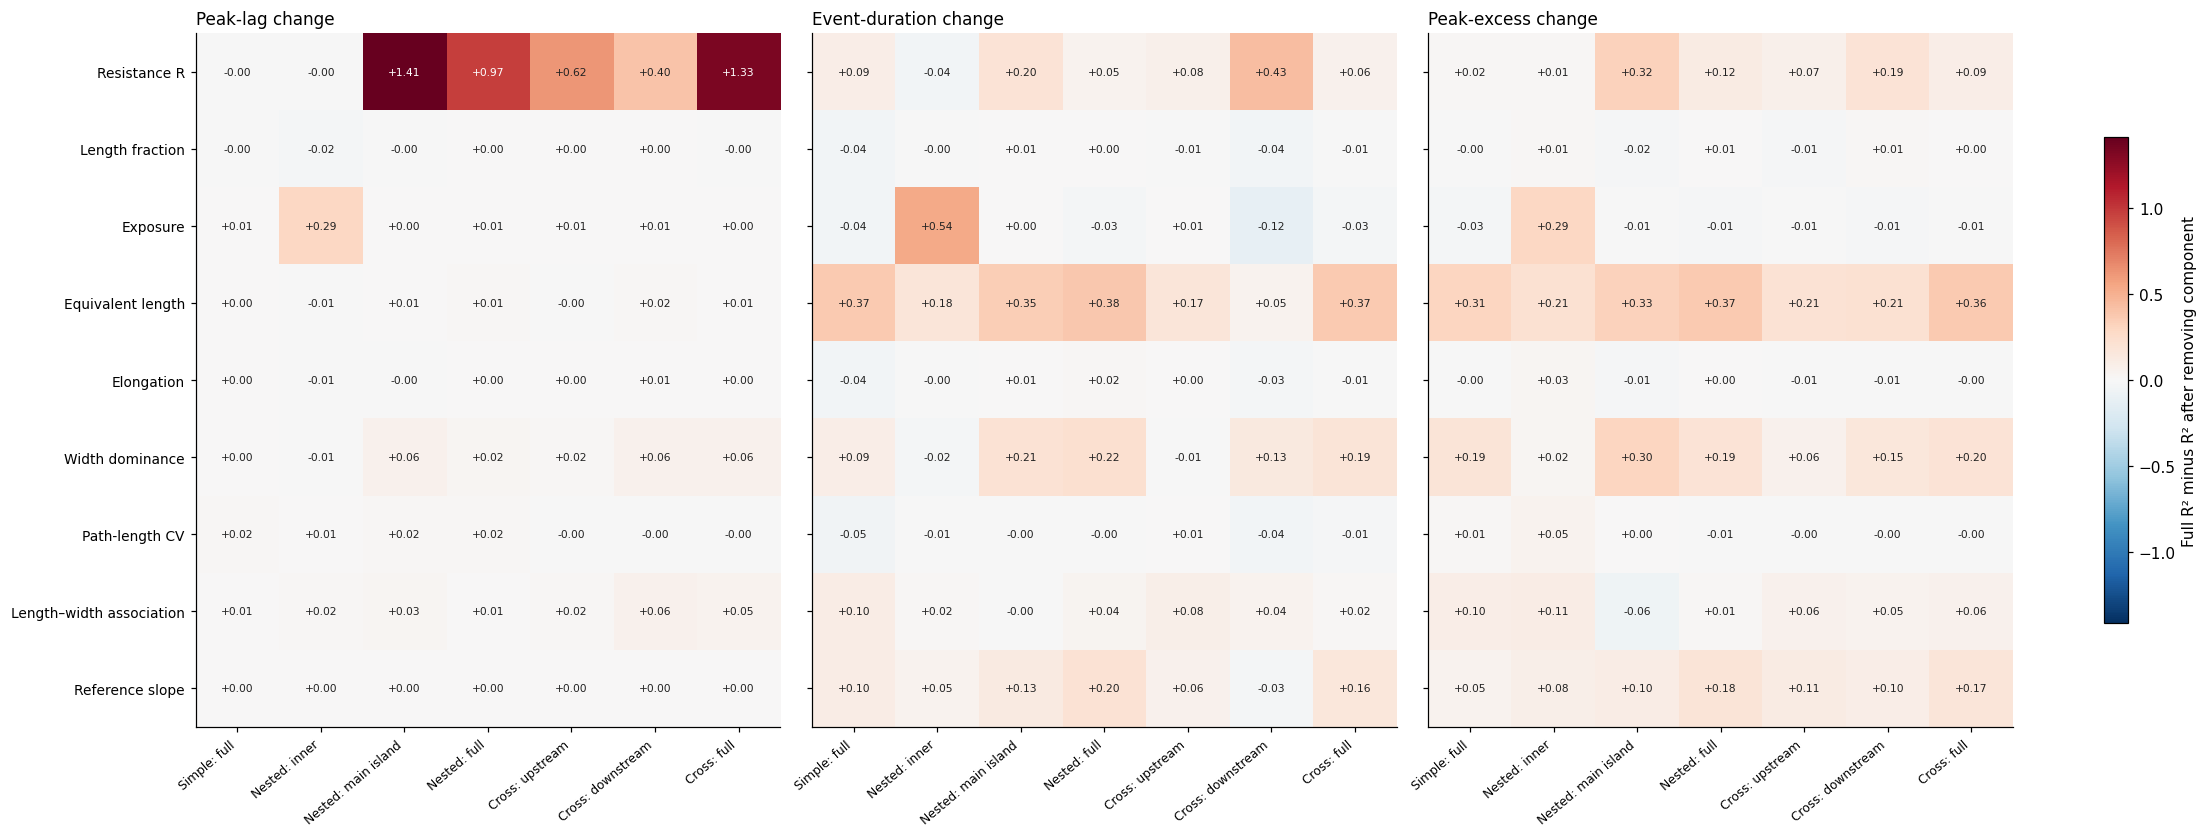

response,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct
feature,,,
domain_reference_slope,0.000,0.097,0.113
length_fraction,-0.003,-0.012,-0.000
parent_dominant_width_fraction,0.032,0.115,0.159
parent_elongation,0.002,-0.008,-0.001
parent_equivalent_length,0.006,0.266,0.285
parent_path_length_cv,0.007,-0.017,0.006
resistance_log,0.676,0.124,0.118
signed_length_width_association,0.028,0.043,0.046
width_fraction,0.046,0.048,0.031


In [8]:
h=scores[(scores.validation=='geometry_group_holdout')&(scores.model=='boosted')&(scores.child_state!='pooled')]
full=h[h.feature_set=='components_plus_all'].set_index(['response','child_state']).r2
rows=[]
for feature,label in metric_names.items():
    reduced=h[h.feature_set=='drop_'+feature].set_index(['response','child_state']).r2
    for (response,state),loss in (full-reduced).items():rows.append(dict(feature=feature,response=response,child_state=state,loss=loss))
abl=pd.DataFrame(rows);limit=max(abs(abl.loss.min()),abs(abl.loss.max()))
fig,axes=plt.subplots(1,3,figsize=(20,7.5),constrained_layout=True)
for j,(ax,y,label) in enumerate(zip(axes,Y,YL)):
    mat=abl[abl.response==y].pivot(index='feature',columns='child_state',values='loss').reindex(index=metric_names,columns=STATES)
    im=heat(ax,mat,list(metric_names.values()) if j==0 else ['']*len(metric_names),SL,label,-limit,limit,'RdBu_r',fmt='+.2f')
fig.colorbar(im,ax=axes,label='Full R² minus R² after removing component',shrink=.7)
savefig(fig,'current_predictor_ablation.png')
display(abl.groupby(['feature','response']).loss.mean().unstack()[Y].round(3))


## 7. Dependence on model family and transfer to unseen treatments

The older analyses were not all one model: the multivariable synthetic screens mainly used boosted trees, scalar product searches used spline/Ridge curves, and the real pilot used linear Ridge. The comparison below places three model families on the same inputs, responses and split.

Differences between model families indicate how much the selected-run mapping benefits from linear, additive or interacting models. They do not establish a physical mechanism.

For the transfer panels, withhold every configuration of one collapse treatment, fit on the other six, then evaluate the omitted one. Geometry groups do not cross treatment labels in this dataset. A geometrically related treatment can remain in training, so this is still not an independent river test.

response                             lag_shift_pct  ...  peak_excess_change_pct
model           feature_set                         ...                        
additive_spline compact                      0.483  ...                   0.224
                components                   0.433  ...                  -0.063
                components_plus_all          0.768  ...                   0.442
                omega                        0.299  ...                  -0.187
                omega_plus_all               0.713  ...                   0.384
boosted         compact                      0.861  ...                   0.626
                components                   0.765  ...                   0.130
                components_plus_all          0.921  ...                   0.799
                omega                        0.547  ...                   0.003
                omega_plus_all               0.929  ...                   0.782
linear          compact                      0.381  ...                   0.150
                components                   0.325  ...                  -0.069
                components_plus_all          0.673  ...                   0.295
                omega                        0.301  ...                  -0.186
                omega_plus_all               0.665  ...                   0.262

[15 rows x 3 columns]

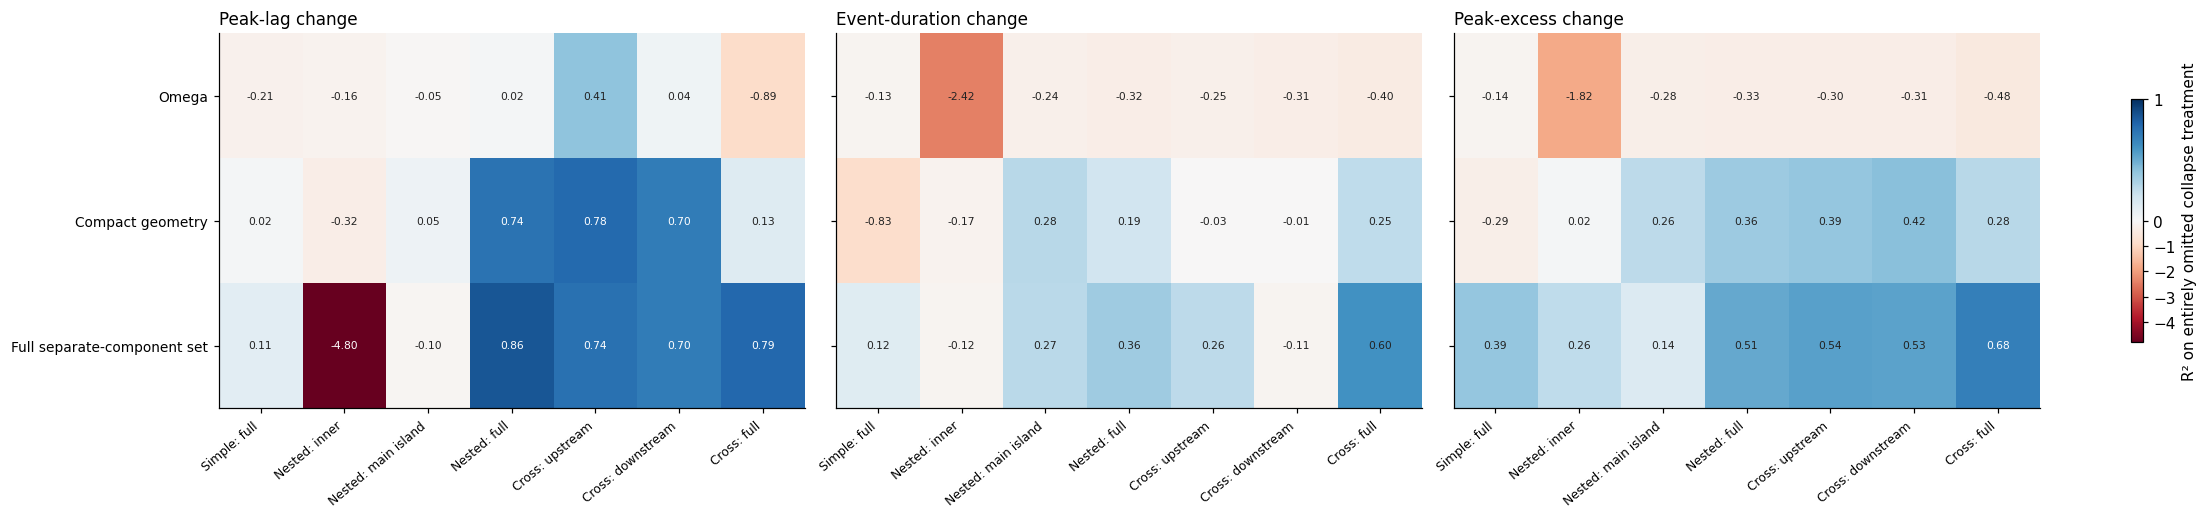

response,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct
feature_set,,,
compact,0.299,-0.044,0.206
components_plus_all,-0.244,0.197,0.437
omega,-0.120,-0.580,-0.522


In [9]:
summary=scores[(scores.validation=='geometry_group_holdout')&(scores.child_state!='pooled')&scores.feature_set.isin(GROUPS)].groupby(['model','feature_set','response']).r2.mean().unstack()[Y]
display(summary.round(3))
transfer_groups=['omega','compact','components_plus_all'];transfer_labels=['Omega','Compact geometry','Full separate-component set']
t=scores[(scores.validation=='leave_collapse_type_out')&(scores.child_state!='pooled')]
fig,axes=plt.subplots(1,3,figsize=(20,4.6),constrained_layout=True)
low=min(-1,float(t.r2.min()))
for j,(ax,y,label) in enumerate(zip(axes,Y,YL)):
    mat=t[t.response==y].pivot(index='feature_set',columns='child_state',values='r2').reindex(index=transfer_groups,columns=STATES)
    im=heat(ax,mat,transfer_labels if j==0 else ['']*3,SL,label,low,1,'RdBu',fmt='.2f')
fig.colorbar(im,ax=axes,label='R² on entirely omitted collapse treatment',shrink=.65)
savefig(fig,'current_predictor_type_transfer.png')
display(t.groupby(['feature_set','response']).r2.mean().unstack()[Y].round(3))


## Fixed benchmark and the hydraulic revision

The benchmark uses the same inputs, estimators and partitions as before, fitted to the new responses and local-kb resistance. Read the current tables and the old-versus-new benchmark comparison below. No legacy R² values are presented as selected-run results.

## Extension: do original-grid predictors transfer?

The full 140-configuration extension is scored without fitting to extension rows. Candidate specifications selected within the original grid are rebuilt using its development rows only. Matching original-grid anchors must reproduce responses and descriptors and are excluded from extension scores. This is exploratory extrapolation, not real-network validation.

In [10]:
import sys
sys.path.insert(0,str(ROOT/'synthetic_experiments/investigations'))
from embedded_predictor_validation import load_extension
extension_raw,extension_phase=load_extension()
EXTENSION_OUT=ACTIVE_EXTENSION
EXTENSION_VALIDATION=EXTENSION_OUT/'predictor_validation'
provenance_path=EXTENSION_VALIDATION/f'{extension_phase}_provenance.json'
if not provenance_path.exists():
    raise RuntimeError('Run investigations/embedded_predictor_validation.py for the current extension phase.')
extension_provenance=json.loads(provenance_path.read_text())
assert extension_provenance['plan_id']==json.loads((EXTENSION_OUT/'manifest.json').read_text())['plan_id'], 'Regenerate extension predictor files: plan changed.'
extension_predictions=pd.read_parquet(EXTENSION_VALIDATION/f'{extension_phase}_predictions.parquet')
extension_scores=pd.read_csv(EXTENSION_VALIDATION/f'{extension_phase}_scores.csv')
extension_ranges=pd.read_csv(EXTENSION_VALIDATION/f'{extension_phase}_feature_ranges.csv')
print(f"EXTENSION {extension_phase.upper()}: {extension_provenance['n_scored_novel_rows']} novel comparisons; {extension_provenance['n_excluded_anchors']} original-grid anchors excluded.")
print(extension_provenance['training'])
extension_models=['omega','three_axes','selected_shared','selected_plus_change','selected_plus_change_context']
extension_labels=['Omega','Best three axes','Selected shared','Selected + collapse change','Selected + change + surroundings']
display(pd.DataFrame({'Model':extension_labels,'Inputs':[', '.join(metric_names.get(c,c) for c in extension_provenance['feature_sets'][m]) for m in extension_models]}))
display(extension_ranges.rename(columns={'outside_fraction':'fraction_outside_training_range'}).round(5))


EXTENSION FULL: 917 novel comparisons; 63 original-grid anchors excluded.
original development rows only, fixed boosted model, no feature reselection or parameter tuning


,Model,Inputs
0,Omega,omega
1,Best three axes,"omega, Equivalent length, Width dominance"
2,Selected shared,"Resistance R, Exposure, Equivalent length, Wid..."
3,Selected + collapse change,"Resistance R, Exposure, Equivalent length, Wid..."
4,Selected + change + surroundings,"Resistance R, Exposure, Equivalent length, Wid..."


,feature,training_min,training_max,extension_min,extension_max,fraction_outside_training_range
0,omega,0.03646,0.55659,0.00029,0.65217,0.62268
1,parent_equivalent_length,2000.00000,29000.00000,4000.00000,29000.00000,0.00000
2,parent_dominant_width_fraction,0.40911,0.90000,0.39709,0.95000,0.17884
3,resistance_log,0.05166,0.77067,0.01229,0.85597,0.13086
4,width_fraction,0.50000,1.00000,0.05000,1.00000,0.06543
5,signed_length_width_association,-0.12000,0.16000,-0.45000,0.45000,0.13086
6,domain_reference_slope,0.00005,0.00050,0.00010,0.00010,0.00000
7,log_equivalent_length_ratio,-0.37156,0.00603,-1.06471,0.01235,0.13086
8,log_elongation_ratio,-0.37156,0.32622,-1.06471,0.34156,0.10469
9,change_path_length_cv,-0.20000,0.00252,-0.50000,0.00252,0.24427


### Accuracy outside the original grid

Negative R² means worse squared error than predicting the treatment’s observed extension mean. Read it alongside mean absolute error in percentage points and sample counts. Full-extension scores and original-grid holdout scores have different test distributions.

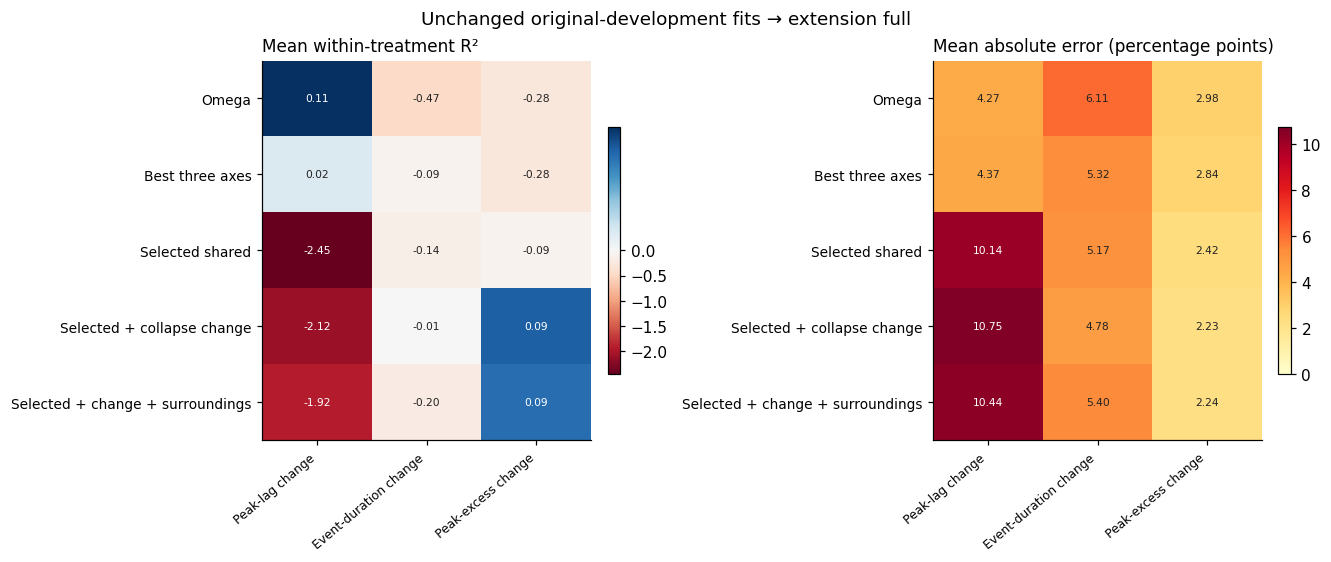

mean_treatment_r2  ...  comparisons
scope          model                        response                                      ...             
novel_20km     omega                        event_duration_change_pct             -1.000  ...          182
                                            lag_shift_pct                          0.082  ...          182
                                            peak_excess_change_pct                -0.587  ...          182
               selected_plus_change         event_duration_change_pct             -0.530  ...          182
                                            lag_shift_pct                          0.542  ...          182
                                            peak_excess_change_pct                -0.265  ...          182
               selected_plus_change_context event_duration_change_pct             -0.594  ...          182
                                            lag_shift_pct                          0.574  ...          182
                                            peak_excess_change_pct                -0.271  ...          182
               selected_shared              event_duration_change_pct             -0.708  ...          182
                                            lag_shift_pct                          0.294  ...          182
                                            peak_excess_change_pct                -0.420  ...          182
               three_axes                   event_duration_change_pct             -0.662  ...          182
                                            lag_shift_pct                          0.190  ...          182
                                            peak_excess_change_pct                -0.592  ...          182
novel_all      omega                        event_duration_change_pct             -0.468  ...          917
                                            lag_shift_pct                          0.114  ...          917
                                            peak_excess_change_pct                -0.284  ...          917
               selected_plus_change         event_duration_change_pct             -0.008  ...          917
                                            lag_shift_pct                         -2.123  ...          917
                                            peak_excess_change_pct                 0.093  ...          917
               selected_plus_change_context event_duration_change_pct             -0.205  ...          917
                                            lag_shift_pct                         -1.917  ...          917
                                            peak_excess_change_pct                 0.087  ...          917
               selected_shared              event_duration_change_pct             -0.138  ...          917
                                            lag_shift_pct                         -2.454  ...          917
                                            peak_excess_change_pct                -0.088  ...          917
               three_axes                   event_duration_change_pct             -0.092  ...          917
                                            lag_shift_pct                          0.017  ...          917
                                            peak_excess_change_pct                -0.279  ...          917
novel_embedded omega                        event_duration_change_pct             -0.423  ...          735
                                            lag_shift_pct                         -2.398  ...          735
                                            peak_excess_change_pct                -0.277  ...          735
               selected_plus_change         event_duration_change_pct              0.083  ...          735
                                            lag_shift_pct                        -28.756  ...          735
                                            peak_excess_change_pct                 0.156  ...          735
     

In [11]:
extension_summary=extension_scores.query("scope=='novel_all' and child_state!='pooled'").groupby(['model','response'])[['r2','mae_pp']].mean()
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,metric,title in zip(axes,['r2','mae_pp'],['Mean within-treatment R²','Mean absolute error (percentage points)']):
    table=extension_summary[metric].unstack().reindex(index=extension_models,columns=Y)
    lo=min(-.01,float(table.min().min())) if metric=='r2' else 0
    hi=max(.01,float(table.max().max()))
    im=heat(ax,table,extension_labels,YL,title,lo,hi,'RdBu' if metric=='r2' else 'YlOrRd',fmt='.2f')
    fig.colorbar(im,ax=ax,shrink=.65)
fig.suptitle(f'Unchanged original-development fits → extension {extension_phase}')
fig.savefig(EXTENSION_VALIDATION/f'{extension_phase}_accuracy.png',dpi=170,bbox_inches='tight');display(fig);plt.close(fig)
extension_scope=extension_scores.query("child_state!='pooled'").groupby(['scope','model','response']).agg(mean_treatment_r2=('r2','mean'),mae_pp=('mae_pp','mean'),comparisons=('n','sum'))
display(extension_scope.round(3))


### Where the errors occur

The plot shows the development-selected shared model with change/context additions. Colour identifies network extent; crosses identify lag changes within one timestep. Inspect errors and out-of-range inputs without using extension scores for feature selection. Good deterministic interpolation does not establish a universal predictor.

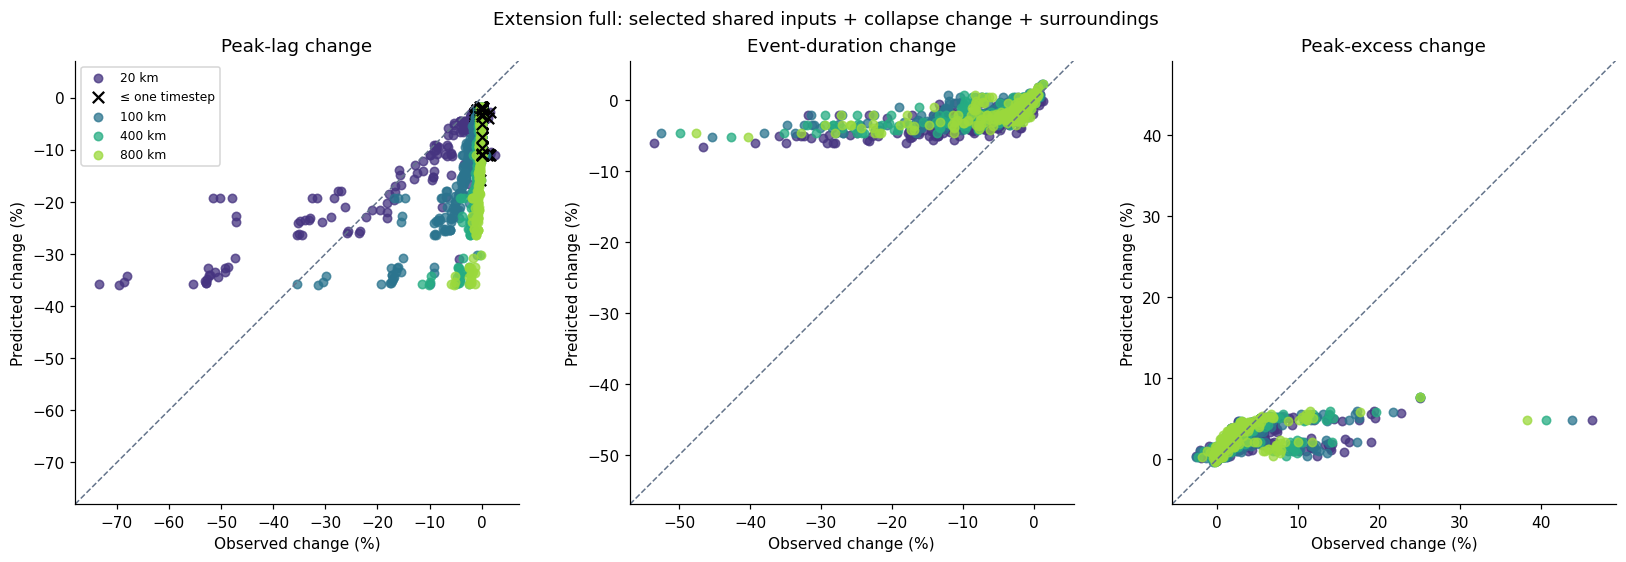

In [12]:
extension_plot=extension_predictions[(extension_predictions.model=='selected_plus_change_context')&(~extension_predictions.is_original_grid_anchor)]
fig,axes=plt.subplots(1,3,figsize=(15,5),constrained_layout=True)
extension_extents=sorted(extension_plot.network_extent_m.unique())
extension_colors=dict(zip(extension_extents,plt.get_cmap('viridis')(np.linspace(.15,.85,len(extension_extents)))))
for ax,y,label in zip(axes,Y,YL):
    subset=extension_plot[extension_plot.response==y]
    for extent,g in subset.groupby('network_extent_m'):
        ax.scatter(g.observed,g.predicted,s=30,color=extension_colors[extent],label=f'{extent/1000:g} km',alpha=.75)
        if y=='lag_shift_pct':
            flagged=g[g.within_one_dt]
            ax.scatter(flagged.observed,flagged.predicted,marker='x',s=55,color='black',label='≤ one timestep' if extent==extension_extents[0] else None)
    limits=[min(subset.observed.min(),subset.predicted.min()),max(subset.observed.max(),subset.predicted.max())]
    pad=max(1,(limits[1]-limits[0])*.06);limits=[limits[0]-pad,limits[1]+pad]
    ax.plot(limits,limits,color='#64748b',ls='--',lw=1)
    ax.set(xlim=limits,ylim=limits,xlabel='Observed change (%)',ylabel='Predicted change (%)',title=label,aspect='equal')
axes[0].legend(fontsize=8)
fig.suptitle(f'Extension {extension_phase}: selected shared inputs + collapse change + surroundings')
fig.savefig(EXTENSION_VALIDATION/f'{extension_phase}_observed_predicted.png',dpi=170,bbox_inches='tight');display(fig);plt.close(fig)


## Timing-response alternatives: fixed-model comparison

**SYN-2026-09-30-TIMING-OPTIONS.** See synthesis section 6 for meanings and the controlled embedding test. We compare timing definitions using the same shallow boosted estimator, original development rows and geometry-group holdout. All 63 extension anchors are excluded from extension scores. No extension row trains a model and no new subset search is performed.

The selected six inputs are the previously selected reference set, not a newly optimized set for every response. The change block contains log equivalent-length ratio, log elongation ratio and change in path-length CV. Width-dominance change is excluded from this block and tested separately as a controlled addition: its earlier group-level improvement did not establish an individual contribution.

Omega and its separate components remain reference predictors. The local resistance product is exposure × resistance-log, without whole-network length fraction. Timing targets are never predictor inputs. Parent Leq is both a response normalizer and an input, so predictive gains must be read alongside this mathematical coupling.

R² summarizes reproduction of deterministic routing outputs, not physical validity. MAE is exported in each response's own units and must not be compared numerically across different units. Metrics and models are exploratory candidates; the existing primary results above remain unchanged.

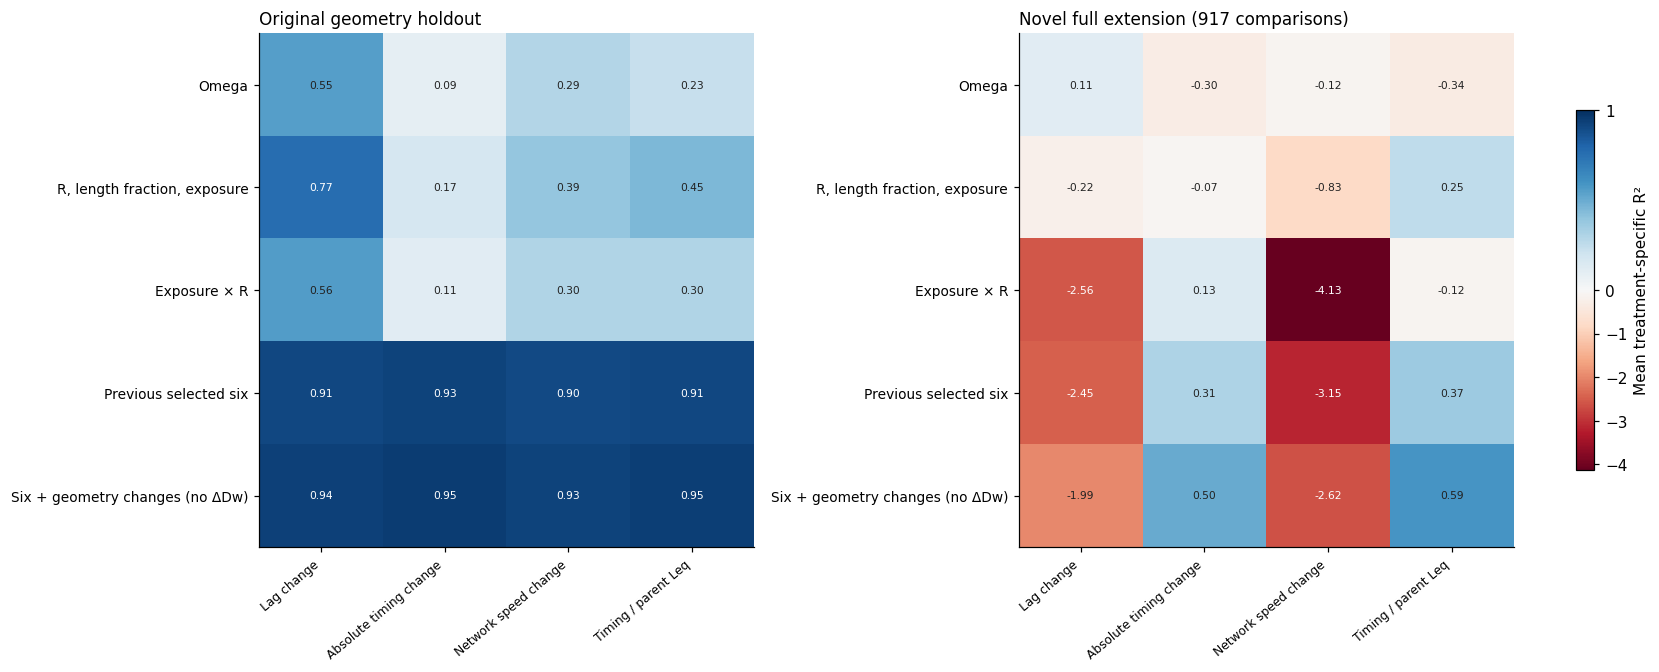

scope,original_holdout,extension_20km,extension_embedded,extension_all
metric,,,,
lag_change_pct,0.937,0.592,-27.708,-1.990
lag_change_hours,0.947,0.345,0.541,0.504
network_speed_change_mps,0.929,0.534,-30.454,-2.622
lag_per_parent_leq_min_km,0.945,0.453,0.631,0.592
reference_speed_change_mps,0.929,0.396,-43.091,-1.928
reference_lag_per_parent_leq_min_km,0.941,0.512,0.410,0.447
equivalent_speed_change_pct,0.893,0.350,-16.605,-2.086


,Group,Inputs
0,omega,omega
1,components,"resistance_log, length_fraction, width_fraction"
2,local_resistance_product,exposure_resistance
3,selected_six,"resistance_log, width_fraction, parent_equival..."
4,six_plus_change_no_delta_dominance,"resistance_log, width_fraction, parent_equival..."
5,six_plus_change_and_context,"resistance_log, width_fraction, parent_equival..."
6,six_plus_change_with_delta_dominance,"resistance_log, width_fraction, parent_equival..."


In [13]:
TIMING=OUT/'timing_response_comparison'
timing_scores=pd.read_csv(TIMING/'predictor_summary.csv')
timing_definitions=pd.read_csv(TIMING/'metric_definitions.csv').set_index('metric')
timing_features=json.loads((TIMING/'feature_sets.json').read_text())
timing_core=['lag_change_pct','lag_change_hours','network_speed_change_mps','lag_per_parent_leq_min_km']
timing_groups=['omega','components','local_resistance_product','selected_six','six_plus_change_no_delta_dominance']
timing_group_names=['Omega','R, length fraction, exposure','Exposure × R','Previous selected six','Six + geometry changes (no ΔDw)']
fig,axes=plt.subplots(1,2,figsize=(15,6),constrained_layout=True)
selected=timing_scores[timing_scores.metric.isin(timing_core)&timing_scores.feature_set.isin(timing_groups)&timing_scores.scope.isin(['original_holdout','extension_all'])]
lo=min(-.1,selected.r2.min())
for ax,scope,title in zip(axes,['original_holdout','extension_all'],['Original geometry holdout','Novel full extension (917 comparisons)']):
 table=selected[selected.scope==scope].pivot(index='feature_set',columns='metric',values='r2').reindex(index=timing_groups,columns=timing_core)
 im=heat(ax,table,timing_group_names,[timing_definitions.loc[k,'label'] for k in timing_core],title,lo,1,'RdBu',fmt='.2f')
fig.colorbar(im,ax=axes,label='Mean treatment-specific R²',shrink=.7)
fig.savefig(TIMING/'timing_predictor_comparison.png',dpi=170,bbox_inches='tight');display(fig);plt.close(fig)
# Keep local extremes and long embeddings distinct rather than masking them in a pooled score.
timing_table=timing_scores[timing_scores.feature_set=='six_plus_change_no_delta_dominance'].pivot(index='metric',columns='scope',values='r2').reindex(timing_definitions.index)
display(timing_table[['original_holdout','extension_20km','extension_embedded','extension_all']].round(3))
display(pd.DataFrame({'Group':timing_features.keys(),'Inputs':[', '.join(v) for v in timing_features.values()]}))


### Does change in width dominance add useful information here?

This compares the same six-plus-change inputs with and without ΔDw. Positive differences mean adding it improved the particular test score; they are not proof of a physical mechanism. Full single-path collapses have ΔDw=1−Dw,parent, making the change redundant there. Compound path weights can share links and should not be interpreted as independent discharge fractions. The test does not change the current candidate pool or claim multi-boundary real units are already validated.

In [14]:
dominance=timing_scores[timing_scores.feature_set.isin(['six_plus_change_no_delta_dominance','six_plus_change_with_delta_dominance'])].pivot(index=['metric','scope'],columns='feature_set',values='r2')
dominance['R2_gain_from_delta_Dw']=dominance.six_plus_change_with_delta_dominance-dominance.six_plus_change_no_delta_dominance
display(dominance[['R2_gain_from_delta_Dw']].unstack('scope').round(3))


feature_set                         R2_gain_from_delta_Dw  ...                 
scope                                      extension_20km  ... original_holdout
metric                                                     ...                 
equivalent_speed_change_pct                         0.038  ...            0.008
lag_change_hours                                   -0.021  ...            0.002
lag_change_pct                                     -0.050  ...           -0.000
lag_per_parent_leq_min_km                           0.074  ...            0.002
network_speed_change_mps                           -0.019  ...            0.001
reference_lag_per_parent_leq_min_km                 0.058  ...            0.001
reference_speed_change_mps                          0.024  ...           -0.001

[7 rows x 4 columns]

### Provisional main-text versus supplementary use

Timing change divided by **parent Leq** is a promising candidate for comparing local collapse impacts: it avoids the simple whole-network percentage dilution and transfers better in the tested extension. Absolute timing remains its dimensional control. Percentage lag and network speed remain useful measures of whole-network consequence; the reference-scaled formulas remain supplementary sensitivity checks because the synthetic centerline is not an observed gauge reference.

This is a provisional interpretation, not a primary-metric replacement or a final feature selection. Peak reshaping still produces embedding dependence. Revisit real gauge timing and the metric's intended meaning before choosing the main-text response, then allow a new compact search to replace original features with defensible change descriptors. Preserve the alternatives and their failed transfer tests as supporting evidence.

## Previous versus selected hydraulic setup

These changes include the move from kb=20/n=.35 to BASED-reference local kb/alpha=.65/n=.035. They are not an alpha-only contrast. Geometry, response definitions and validation partitions are matched; earlier outputs remain preserved.

In [15]:
previous_selected=pd.read_csv(ACTIVE_RUN.parent/'old_new_predictor_summary.csv')
# Treatment-averaged held-out scores for the same fixed boosted estimator.
display(previous_selected[(previous_selected.model=='boosted') & previous_selected.feature_set.isin(['omega','components','compact','components_plus_all'])].round(4))
print('Complete three-model comparison:',ACTIVE_RUN.parent/'old_new_predictor_summary.csv')

Complete three-model comparison: /Users/6256481/Code/river-hierarchy/synthetic_experiments/outputs/hydraulic_alpha065_20260930/old_new_predictor_summary.csv


,model,feature_set,response,r2_previous,r2_selected,mae_pp_previous,mae_pp_selected,r2_change
24,boosted,compact,event_duration_change_pct,0.5443,0.5186,6.7432,1.3692,-0.0258
25,boosted,compact,lag_shift_pct,0.7631,0.8614,2.8818,1.4533,0.0984
26,boosted,compact,peak_excess_change_pct,0.5305,0.6259,6.2034,1.0285,0.0954
27,boosted,components,event_duration_change_pct,0.1411,0.1057,9.5062,2.0940,-0.0355
28,boosted,components,lag_shift_pct,0.6530,0.7653,3.5670,1.9493,0.1123
29,boosted,components,peak_excess_change_pct,0.0214,0.1298,9.2881,1.6949,0.1084
30,boosted,components_plus_all,event_duration_change_pct,0.6910,0.7050,4.9855,0.9631,0.0140
31,boosted,components_plus_all,lag_shift_pct,0.8493,0.9214,2.2794,1.0296,0.0721
32,boosted,components_plus_all,peak_excess_change_pct,0.7404,0.7995,4.0929,0.7179,0.0590
66,boosted,omega,event_duration_change_pct,0.0260,-0.0049,10.2497,2.1612,-0.0309
